Geoinformatik 2 – GIS-Analyse
# Übung 8: Punktmusteranalyse mit Ripley Funktionen
Prof. Dr. Yu Feng

## Lernziele
- Reale räumliche Punktmuster analysieren (Flickr Nutzerfotos)
- Beobachtete Muster mit CSR und regulären Referenzen vergleichen
- Ripley's G, F, K, L Funktionen anwenden

In [7]:
import importlib.util
import json
import subprocess
import sys
from pathlib import Path
from urllib.parse import urlencode
from urllib.request import urlopen

try:
    import google.colab
except ModuleNotFoundError as exc:
    if exc.name not in ("google", "google.colab"):
        raise
    in_colab = False
else:
    in_colab = True

packages = [
    "numpy", "pandas", "geopandas", "seaborn", "contextily", "matplotlib",
    "shapely", "pointpats", "libpysal", "mapclassify", "folium",
]
missing = [name for name in packages if importlib.util.find_spec(name) is None]
if missing:
    if not in_colab:
        raise ModuleNotFoundError(
            "Fehlende Pakete im Notebook-Kernel. Installieren Sie diese mit: %pip install "
            + " ".join(missing)
        )
    subprocess.run([sys.executable, "-m", "pip", "install", *missing], check=True)
    importlib.invalidate_caches()

if in_colab:
    data_dir = Path("/content/data")
elif Path.cwd().name == "Uebung7":
    data_dir = Path.cwd() / "data"
elif (Path.cwd() / "Uebung7").is_dir():
    data_dir = Path.cwd() / "Uebung7" / "data"
else:
    raise FileNotFoundError("Jupyter bitte im Repository oder im Ordner Uebung7 starten.")
data_dir.mkdir(parents=True, exist_ok=True)
csv_path = data_dir / "tokyo_clean.csv"
boundary_path = data_dir / "Greater_Tokyo_Area.geojson"

csv_url = "https://raw.githubusercontent.com/gdsbook/book/master/data/tokyo/tokyo_clean.csv"
if not csv_path.is_file():
    with urlopen(csv_url, timeout=120) as response:
        csv_data = response.read()
    with csv_path.open("xb") as output:
        output.write(csv_data)

boundary_url = (
    "https://services.arcgis.com/P3ePLMYs2RVChkJx/arcgis/rest/services/"
    "JPN_Boundaries_ECM/FeatureServer/1/query?"
    + urlencode({
        "where": "KEN IN ('08','09','10','11','12','13','14','19')",
        "outFields": "*",
        "outSR": "4326",
        "f": "geojson",
    })
)
if not boundary_path.is_file():
    with urlopen(boundary_url, timeout=120) as response:
        boundary_data = json.load(response)
    if (
        boundary_data.get("type") != "FeatureCollection"
        or boundary_data.get("exceededTransferLimit")
        or len(boundary_data.get("features", [])) != 382
    ):
        raise ValueError(f"Grenzdaten unvollständig oder ungültig: {boundary_data.get('error', 'unerwartete Anzahl Regionen')}")
    with boundary_path.open("x", encoding="utf-8") as output:
        json.dump(boundary_data, output, ensure_ascii=False)

print(f"Umgebung: {'Google Colab' if in_colab else 'lokal'}; Daten: {data_dir.resolve()}")

Umgebung: Google Colab; Daten: /content/data


In [8]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pointpats import distance_statistics, random

# Set random seed for reproducibility
np.random.seed(42)

In [9]:
# Lade Tokyo Flickr Fotodaten
db = pd.read_csv("/content/data/tokyo_clean.csv")
print(f"Gesamtanzahl Datensätze: {len(db)}")
db.head(3)

Gesamtanzahl Datensätze: 10000


,user_id,longitude,latitude,date_taken,photo/video_page_url,x,y
0,10727420@N00,139.700499,35.674000,2010-04-09 17:26:25.0,http://www.flickr.com/photos/10727420@N00/4545...,1.555139e+07,4.255856e+06
1,8819274@N04,139.766521,35.709095,2007-02-10 16:08:40.0,http://www.flickr.com/photos/8819274@N04/26503...,1.555874e+07,4.260667e+06
2,62068690@N00,139.765632,35.694482,2008-12-21 15:45:31.0,http://www.flickr.com/photos/62068690@N00/3125...,1.555864e+07,4.258664e+06


In [10]:
# Extrahiere Koordinaten für spezifischen Nutzer (aktivster Fotograf)
user = db.query('user_id == "95795770@N00"')
coordinates = user[["x", "y"]].values
print(f"Nutzerfotos: {len(user)}")
print(f"Koordinaten-Shape: {coordinates.shape}")

Nutzerfotos: 419
Koordinaten-Shape: (419, 2)


## Erzeugung von Referenzmustern: CSR und Regulär

Wir vergleichen das beobachtete Muster (Flickr Nutzer `95795770@N00`) mit:
1. **CSR (Complete Spatial Randomness)** - Poisson-Zufallsprozess
2. **Reguläres Muster** - Gitter mit kleinem Rauschen zur Vermeidung von Artefakten

Ziel: Ripley G/F/K/L Funktionen nutzen, um Unterschiede zwischen Clusterung, Regularität und Zufälligkeit zu analysieren.
Referenz: Geographic Data Science Book - Point Pattern Analysis.

In [11]:
# Erzeuge Referenzmuster

# Bounding Box aus beobachteten Koordinaten
x_min, x_max = coordinates[:,0].min(), coordinates[:,0].max()
y_min, y_max = coordinates[:,1].min(), coordinates[:,1].max()
width = x_max - x_min
height = y_max - y_min

n_points_obs = coordinates.shape[0]
print(f"Beobachtet: {n_points_obs} Punkte")

# CSR: Poisson-Zufallsprozess innerhalb Bounding Box
random_pattern = random.poisson(coordinates, size=n_points_obs)
print(f"CSR erzeugt: {len(random_pattern)} Punkte")

# Regulär: Gitter mit Rauschen zur Vermeidung von Stufenartefakten in Ripley-Funktionen
n_side = int(np.ceil(np.sqrt(n_points_obs)))
x_regular = np.linspace(x_min, x_max, n_side)
y_regular = np.linspace(y_min, y_max, n_side)
xx, yy = np.meshgrid(x_regular, y_regular)
regular_all = np.column_stack([xx.ravel(), yy.ravel()])
regular_pattern = regular_all[:n_points_obs]
# Füge kleines Rauschen hinzu (0.5% der min. Dimension) um perfekte Regularität zu brechen
noise = np.random.normal(0, 0.005 * min(width, height), size=regular_pattern.shape)
regular_pattern = regular_pattern + noise
regular_pattern = np.clip(regular_pattern, [x_min, y_min], [x_max, y_max])
print(f"Regulär erzeugt: {len(regular_pattern)} Punkte (Gitter + Rauschen)")

Beobachtet: 419 Punkte
CSR erzeugt: 419 Punkte
Regulär erzeugt: 419 Punkte (Gitter + Rauschen)


## Visualisierung der Muster

Räumliche Verteilung aller drei Muster: Beobachtet, CSR Zufällig und Reguläres Gitter.

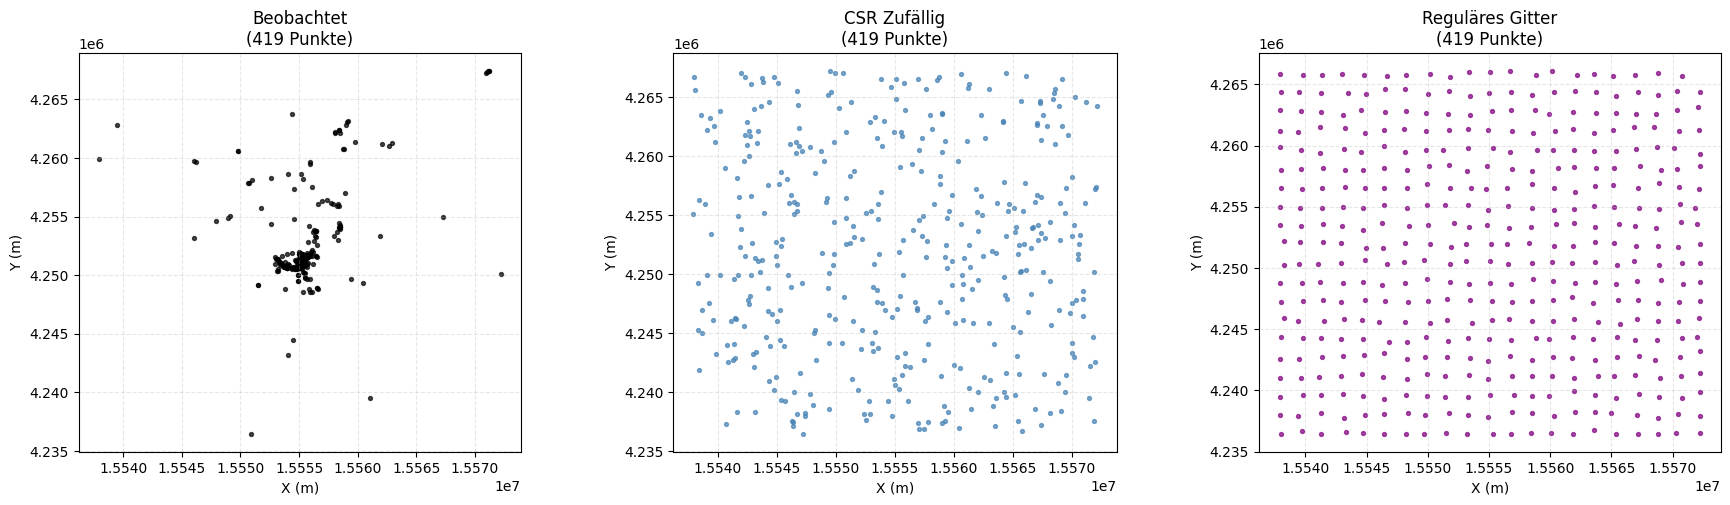

In [12]:
# Visualisierung: Beobachtet vs CSR vs Regulär
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
patterns = [
    (coordinates, "Beobachtet", "black", axes[0]),
    (random_pattern, "CSR Zufällig", "steelblue", axes[1]),
    (regular_pattern, "Reguläres Gitter", "purple", axes[2]),
]

for pts, title, color, ax in patterns:
    ax.scatter(pts[:,0], pts[:,1], s=8, color=color, alpha=0.7)
    ax.set_aspect('equal')
    ax.set_title(f"{title}\n({len(pts)} Punkte)")
    ax.set_xlabel('X (m)')
    ax.set_ylabel('Y (m)')
    ax.grid(alpha=0.3, linestyle='--')

plt.tight_layout()
plt.savefig('observed_csr_regular.png', dpi=150)
plt.show()

## Nearest Neighbour Index (NNI)

Der NNI vergleicht den beobachteten mittleren Abstand zum nächsten Nachbarn mit seinem theoretischen Erwartungswert unter vollständiger räumlicher Zufälligkeit (CSR). Ein Wert **NNI < 1** weist auf Clusterung hin, **NNI ≈ 1** ist mit CSR vereinbar und **NNI > 1** weist auf Regularität hin.

Für ein Muster mit $n$ Punkten in einer Fläche $A$ gilt:

$$\lambda=\frac{n}{A}$$

$\lambda$ ist die Punktdichte, also die Anzahl der Punkte pro Flächeneinheit.

$$\bar d_{\mathrm{CSR}}=\frac{1}{2\sqrt{\lambda}}$$

$\bar d_{\mathrm{CSR}}$ ist der theoretisch erwartete mittlere Abstand zum nächsten Nachbarn unter CSR.

$$NNI=\frac{\bar d_{\mathrm{obs}}}{\bar d_{\mathrm{CSR}}}$$

Der NNI setzt den beobachteten mittleren Nächster-Nachbar-Abstand $\bar d_{\mathrm{obs}}$ ins Verhältnis zum CSR-Erwartungswert.

$$Z=\frac{\bar d_{\mathrm{obs}}-\bar d_{\mathrm{exp}}}{SE}$$

Dabei ist $\bar d_{\mathrm{exp}} = \bar d_{\mathrm{CSR}}$ der erwartete mittlere NN-Abstand. Sein Standardfehler $SE = SE_{NN}$ beträgt:

$$SE_{NN}=\frac{0.26136}{\sqrt{\frac{n^2}{A}}}$$

Der Z-Wert gibt an, um wie viele geschätzte Standardfehler der beobachtete mittlere Abstand vom CSR-Erwartungswert abweicht.

Der Z-Test verwendet eine theoretische Approximation ohne Randeffektkorrektur. Berechnen Sie NNI und Z für das beobachtete Muster sowie die CSR- und reguläre Referenz. Für alle drei Muster wird dieselbe rechteckige Untersuchungsfläche ($A=\texttt{width} \times \texttt{height}$) verwendet.

,Mittlerer NN-Abstand (m),Erwarteter NN-Abstand (m),NNI,Z-Wert
Punktmuster,,,,
Beobachtet,210.870680,795.679778,0.26502,-28.781518
CSR,799.785135,795.679778,1.00516,0.202046
Regulär,1393.736756,795.679778,1.75163,29.433515


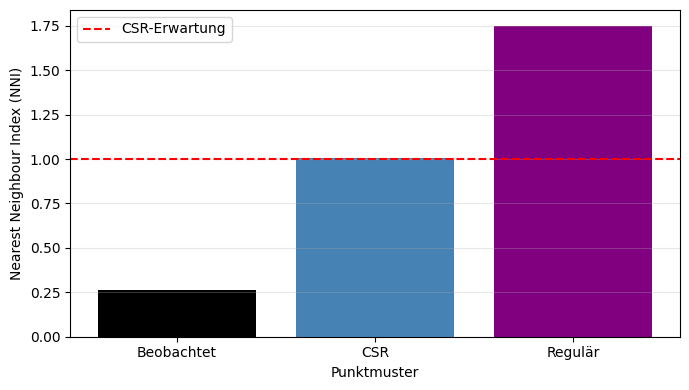

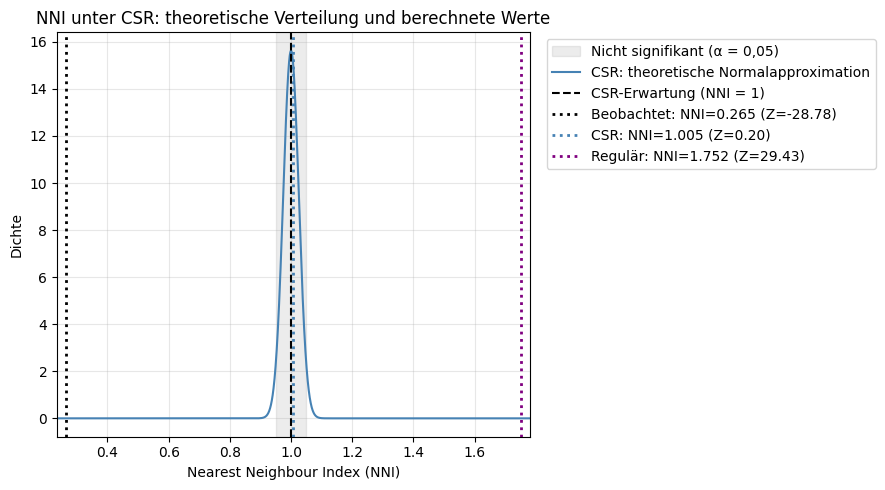

In [16]:
from scipy.spatial import cKDTree
from IPython.display import display

area = width * height

def calculate_nni(points, area):
    n = len(points)
    tree = cKDTree(points)
    distances, _ = tree.query(points, k=2)

    # Der erste Abstand gehört zum Punkt selbst; der zweite ist der nächste Nachbar.
    d_obs = np.mean(distances[:, 1])
    # TODO: Berechne Punktdichte, CSR-Erwartung, NNI und Z-Wert anhand der Formeln.
    # Ersetze die folgende Zeile durch deine vier Berechnungen.
    # raise NotImplementedError('Bitte density, d_csr, nni und z_score berechnen.') -> löst absichtlich Error aus

    # density = ...
    # d_csr = ...
    # nni = ...
    # z_score = ...

    # Punktdichte
    density = n / area

    # Erwarteter mittlerer NN-Abstand unter CSR
    d_csr = 1 / (2 * np.sqrt(density))

    # Nearest Neighbour Index
    nni = d_obs / d_csr

    # Z-Wert
    se = 0.26136 / np.sqrt(n * density)
    z_score = (d_obs - d_csr) / se


    return {
        "Anzahl Punkte": n,
        "Mittlerer NN-Abstand (m)": d_obs,
        "Erwarteter NN-Abstand (m)": d_csr,
        "NNI": nni,
        "Z-Wert": z_score,
    }

pattern_results = [
    ("Beobachtet", coordinates),
    ("CSR", random_pattern),
    ("Regulär", regular_pattern),
]

results = pd.DataFrame(
    [{"Punktmuster": name, **calculate_nni(points, area)} for name, points in pattern_results]
).set_index("Punktmuster")
results = results[[
    "Mittlerer NN-Abstand (m)",
    "Erwarteter NN-Abstand (m)",
    "NNI",
    "Z-Wert",
]]
display(results)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(results.index, results["NNI"], color=["black", "steelblue", "purple"])
ax.axhline(1, color="red", linestyle="--", label="CSR-Erwartung")
ax.set_xlabel("Punktmuster")
ax.set_ylabel("Nearest Neighbour Index (NNI)")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Aus der Z-Formel folgt unter CSR näherungsweise NNI ~ N(1, (0.52272 / sqrt(n))^2).
n = len(coordinates)
nni_sigma = 0.52272 / np.sqrt(n)
x_min_plot = min(1 - 4 * nni_sigma, results["NNI"].min() - 0.03)
x_max_plot = max(1 + 4 * nni_sigma, results["NNI"].max() + 0.03)
nni_x = np.unique(np.concatenate([
    np.linspace(x_min_plot, x_max_plot, 500),
    np.linspace(1 - 4 * nni_sigma, 1 + 4 * nni_sigma, 500),
]))
nni_density = np.exp(-0.5 * ((nni_x - 1) / nni_sigma) ** 2) / (nni_sigma * np.sqrt(2 * np.pi))
critical_lower = 1 - 1.96 * nni_sigma
critical_upper = 1 + 1.96 * nni_sigma

fig, ax = plt.subplots(figsize=(9, 5))
ax.axvspan(critical_lower, critical_upper, color="gray", alpha=0.15, label="Nicht signifikant (α = 0,05)")
ax.plot(nni_x, nni_density, color="steelblue", label="CSR: theoretische Normalapproximation")
ax.axvline(1, color="black", linestyle="--", label="CSR-Erwartung (NNI = 1)")

for name, color in zip(results.index, ["black", "steelblue", "purple"]):
    value = results.loc[name, "NNI"]
    z_value = results.loc[name, "Z-Wert"]
    ax.axvline(value, color=color, linestyle=":", linewidth=2, label=f"{name}: NNI={value:.3f} (Z={z_value:.2f})")

ax.set_xlim(x_min_plot, x_max_plot)
ax.set_xlabel("Nearest Neighbour Index (NNI)")
ax.set_ylabel("Dichte")
ax.set_title("NNI unter CSR: theoretische Verteilung und berechnete Werte")
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Interpretationsfragen

1. Welches Punktmuster zeigt den kleinsten bzw. größten NNI?
2. Welche Punktmuster weichen nach dem Z-Test signifikant von CSR ab ($\alpha=0{,}05$)? Verwenden Sie für den zweiseitigen Test $|Z|>1{,}96$.
3. Warum kann der NNI eines simulierten CSR-Musters von 1 abweichen?

## Ripley G-Funktions-Vergleich

Die G-Funktion analysiert die Verteilung der Nächster-Nachbar-Abstände. Anstiegsgeschwindigkeit von G(d):
- **Schneller Anstieg** → Geclustertes Muster
- **Langsamer Anstieg** → Reguläres/verteiltes Muster
- **Moderater Anstieg** → Zufälliges Muster (CSR)

**Hinweis:** Verwenden Sie `distance_statistics` aus der pointpats-Bibliothek, um die verschiedenen Ripley-Funktionen zu berechnen. Dokumentation: https://pysal.org/pointpats/generated/pointpats.g_test.html

Berechne G-Funktionen...
Fertig


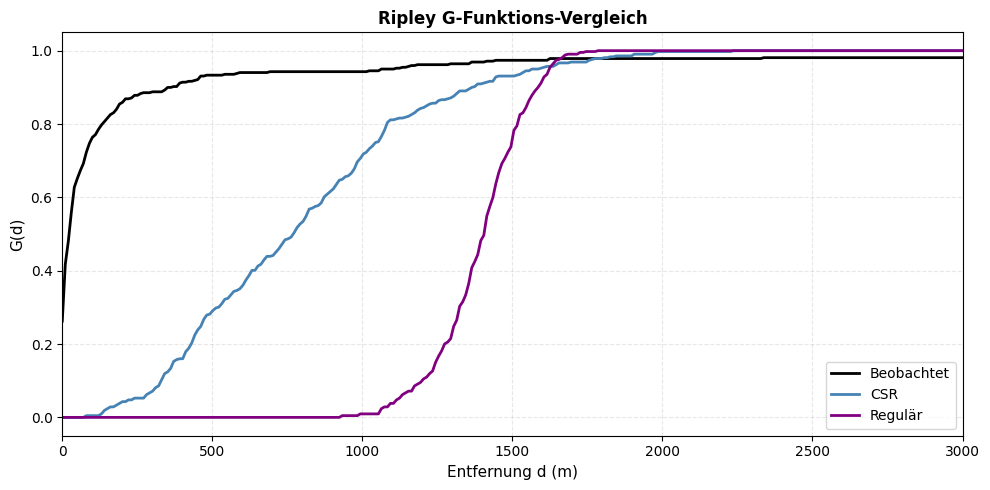


Interpretation:
  Beobachtet steigt viel schneller als CSR → starke Clusterung.
  Regulär steigt am langsamsten → gleichmäßige Verteilung.
  CSR dazwischen als Zufallsreferenz.


In [18]:
# Ripley G-Funktion
print("Berechne G-Funktionen...")

########### Your code here ##############
from types import SimpleNamespace
# g_obs =
# g_csr =
# g_reg =

def calculate_g(points, max_distance=3000, steps=300):
    tree = cKDTree(points)
    distances, _ = tree.query(points, k=2)

    nn_distances = distances[:, 1]
    support = np.linspace(0, max_distance, steps)

    statistic = np.array([
        np.mean(nn_distances <= d) for d in support
    ])

    return SimpleNamespace(
        support=support,
        statistic=statistic
    )

g_obs = calculate_g(coordinates)
g_csr = calculate_g(random_pattern)
g_reg = calculate_g(regular_pattern)
#########################################
print("Fertig")

# Plotte G-Funktion
fig, ax = plt.subplots(figsize=(10,5))
ax.plot(g_obs.support, g_obs.statistic, label='Beobachtet', color='black', linewidth=2)
ax.plot(g_csr.support, g_csr.statistic, label='CSR', color='steelblue', linewidth=2)
ax.plot(g_reg.support, g_reg.statistic, label='Regulär', color='purple', linewidth=2)
ax.set_xlabel('Entfernung d (m)', fontsize=11)
ax.set_ylabel('G(d)', fontsize=11)
ax.set_title('Ripley G-Funktions-Vergleich', fontsize=12, fontweight='bold')
ax.set_xlim(0, 3000)
ax.legend(fontsize=10)
ax.grid(alpha=0.3, linestyle='--')
plt.tight_layout()
plt.savefig('ripley_g_obs_csr_reg.png', dpi=150)
plt.show()

print('\nInterpretation:')
print('  Beobachtet steigt viel schneller als CSR → starke Clusterung.')
print('  Regulär steigt am langsamsten → gleichmäßige Verteilung.')
print('  CSR dazwischen als Zufallsreferenz.')

## Ripley F-Funktions-Vergleich

Die F-Funktion (Leerraum-Funktion) analysiert Abstände von Zufallspunkten zum nächsten Musterpunkt. Anstiegsgeschwindigkeit von F(d):
- **Langsamer Anstieg** → Große Lücken (Clusterung)
- **Schneller Anstieg** → Keine signifikanten Lücken (Regularität)

In [28]:
# Ripley F-Funktion (Leerraum)
print("Berechne F-Funktionen...")
from pointpats import f_test
########### Your code here ##############
# f_obs =
# f_csr =
# f_reg =

f_obs = f_test(coordinates, support=150)
f_csr = f_test(random_pattern, support=150)
f_reg = f_test(regular_pattern, support=150)


#########################################
print("Fertig")

Berechne F-Funktionen...
Fertig


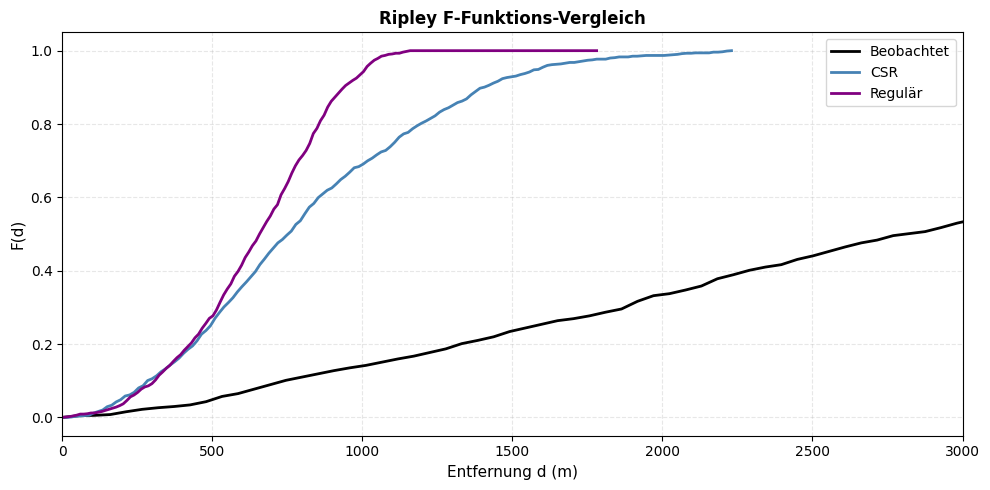


Interpretation:
  CSR dazwischen als Zufallsreferenz.
  Beobachtet steigt langsamer als CSR → größere Leerräume → Clusterung.
  Regulär steigt schneller → minimale große Lücken.


In [29]:
# Plotte F-Funktion
fig, ax = plt.subplots(figsize=(10,5))
ax.plot(f_obs.support, f_obs.statistic, label='Beobachtet', color='black', linewidth=2)
ax.plot(f_csr.support, f_csr.statistic, label='CSR', color='steelblue', linewidth=2)
ax.plot(f_reg.support, f_reg.statistic, label='Regulär', color='purple', linewidth=2)
ax.set_xlabel('Entfernung d (m)', fontsize=11)
ax.set_ylabel('F(d)', fontsize=11)
ax.set_title('Ripley F-Funktions-Vergleich', fontsize=12, fontweight='bold')
ax.set_xlim(0, 3000)
ax.legend(fontsize=10)
ax.grid(alpha=0.3, linestyle='--')
plt.tight_layout()
plt.savefig('ripley_f_obs_csr_reg.png', dpi=150)
plt.show()

print('\nInterpretation:')
print('  CSR dazwischen als Zufallsreferenz.')
print('  Beobachtet steigt langsamer als CSR → größere Leerräume → Clusterung.')
print('  Regulär steigt schneller → minimale große Lücken.')

## Ripley K-Funktions-Vergleich

Die K-Funktion zählt die Anzahl der Punktpaare innerhalb der Entfernung d. Vergleich mit theoretischer Erwartung $K_{CSR}(d) = \pi d^2$:
- $K(d) > \pi d^2$ → Clusterung
- $K(d) = \pi d^2$ → Zufällig
- $K(d) < \pi d^2$ → Regulär/verteilt

In [1]:
# Ripley K-Funktion
print("Berechne K-Funktionen ...")
from pointpats import k_test
########### Your code here ##############
k_obs = k_test(coordinates, support=150)
k_csr = k_test(random_pattern, support=150)
k_reg = k_test(regular_pattern, support=150)

#########################################
print("Fertig")

fig, ax = plt.subplots(figsize=(10,5))
ax.plot(k_obs.support, k_obs.statistic, label='Observed', color='black')
ax.plot(k_csr.support, k_csr.statistic, label='CSR', color='steelblue')
ax.plot(k_reg.support, k_reg.statistic, label='Regular', color='purple')
expected = np.pi * k_csr.support**2
ax.plot(k_csr.support, expected, label='CSR Erwartet πd²', color='green', linestyle='--')
ax.set_xlabel('d (m)')
ax.set_ylabel('K(d)')
ax.set_xlim(0, 3000)
ax.set_title('Ripley K-Funktion Vergleich')
ax.legend(); ax.grid(alpha=0.3, linestyle='--')
plt.tight_layout(); plt.savefig('ripley_k_obs_csr_reg.png', dpi=150); plt.show()

print('\nInterpretation K:')
print('  Observed > Erwartet → mehr Nachbarn als Zufall → Cluster.')
print('  Regular < Erwartet → weniger Paare → gleichmäßig.')
print('  CSR ≈ Erwartet → Referenz.')

Berechne K-Funktionen ...


NameError: name 'coordinates' is not defined

## Ripley L-Funktions-Vergleich

Die L-Funktion ist die normalisierte K-Funktion: $L(d) = \sqrt{K(d)/\pi}$
- Für CSR ist die Erwartung $L(d) = d$
- $L(d) > d$ → Clusterung
- $L(d) = d$ → Zufällig
- $L(d) < d$ → Regulär/verteilt

Die L-Funktion ist einfacher zu interpretieren als die K-Funktion.

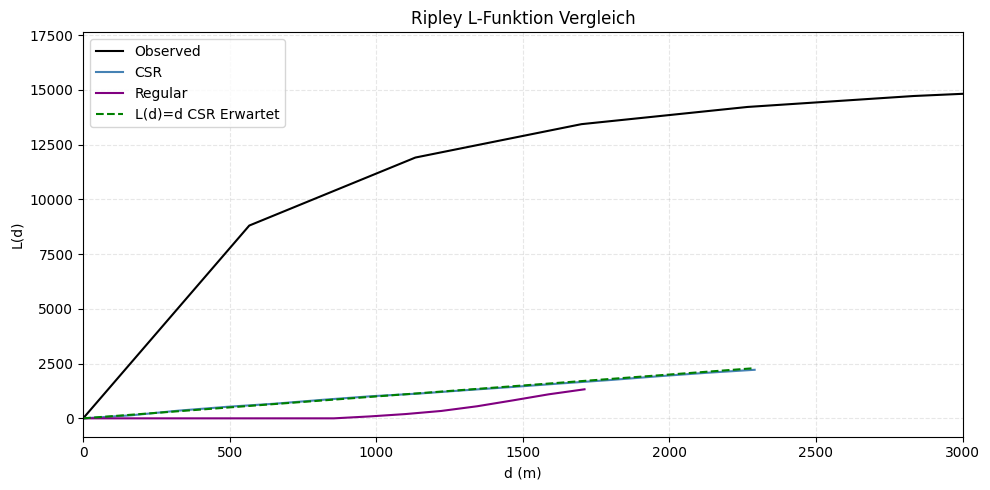


Interpretation L:
  Observed über der Linie → Cluster.
  Regular unter der Linie → Regularität.
  CSR nahe der Linie → Zufälligkeit.


In [ ]:
# Ripley L-Funktion (normalisierte K)
########### Your code here ##############
# L_obs =
# L_csr =
# L_reg =
#########################################

fig, ax = plt.subplots(figsize=(10,5))
ax.plot(k_obs.support, L_obs, label='Observed', color='black')
ax.plot(k_csr.support, L_csr, label='CSR', color='steelblue')
ax.plot(k_reg.support, L_reg, label='Regular', color='purple')
ax.plot(k_csr.support, k_csr.support, label='L(d)=d CSR Erwartet', color='green', linestyle='--')
ax.set_xlabel('d (m)')
ax.set_ylabel('L(d)')
ax.set_xlim(0, 3000)
ax.set_title('Ripley L-Funktion Vergleich')
ax.legend(); ax.grid(alpha=0.3, linestyle='--')
plt.tight_layout(); plt.savefig('ripley_l_obs_csr_reg.png', dpi=150); plt.show()

print('\nInterpretation L:')
print('  Observed über der Linie → Cluster.')
print('  Regular unter der Linie → Regularität.')
print('  CSR nahe der Linie → Zufälligkeit.')

## Ripley L(d) − d

Durch das Abziehen der Entfernung $d$ wird die theoretische CSR-Erwartung auf die Nulllinie verschoben:

$$L(d) - d = \sqrt{\frac{K(d)}{\pi}} - d$$

- $L(d) - d > 0$ → Hinweis auf Clusterung bei der Entfernung $d$
- $L(d) - d \approx 0$ → vereinbar mit der CSR-Erwartung
- $L(d) - d < 0$ → Hinweis auf Regularität bei der Entfernung $d$

Die Abweichung von der Nulllinie allein zeigt keine statistische Signifikanz.

In [ ]:
# Ripley L(d) - d für die drei Punktmuster
fig, ax = plt.subplots(figsize=(10,5))
# TODO: Ersetze jeweils None durch die x- und y-Werte für L(d) - d.
ax.plot(None, None, label='Beobachtet', color='black')
ax.plot(None, None, label='CSR', color='steelblue')
ax.plot(None, None, label='Regulär', color='purple')
ax.axhline(0, label='CSR-Erwartung', color='green', linestyle='--')
ax.set_xlabel('d (m)')
ax.set_ylabel('L(d) - d (m)')
ax.set_xlim(0, 3000)
ax.set_title('Ripley L(d) - d Vergleich')
ax.legend(); ax.grid(alpha=0.3, linestyle='--')
plt.tight_layout(); plt.show()

## Referenz
- Point Pattern Analysis — Geographic Data Science with Python (https://geographicdata.science/book/notebooks/08_point_pattern_analysis.html)
- distance_statistics (https://pysal.org/notebooks/explore/pointpats/distance_statistics.html)